In [1]:

import sys
import torch
import torchvision
import importlib.util
import os

print("Python executable:", sys.executable)
print("Python version:", sys.version.split()[0])
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", "CUDA" if torch.cuda.is_available() else "CPU only")

print("\nBLIP dependency check:")
print("transformers installed:", importlib.util.find_spec("transformers") is not None)
print("Pillow installed:", importlib.util.find_spec("PIL") is not None)

project_dir = r"C:\Users\rajva\Desktop\image-captioning Project"

print("\nProject folder exists:", os.path.isdir(project_dir))
print(
    "Vocabulary exists:",
    os.path.isfile(os.path.join(project_dir, "notebook", "vocabulary.json"))
)
print(
    "Custom checkpoint exists:",
    os.path.isfile(
        os.path.join(
            project_dir,
            "notebook",
            "checkpoints_vit_experiment",
            "vit_transformer_experiment.pth"
        )
    )
)


Python executable: C:\Users\rajva\anaconda3\envs\image_captioning\python.exe
Python version: 3.13.15
PyTorch version: 2.13.0+cpu
Torchvision version: 0.28.0+cpu
Device: CPU only

BLIP dependency check:
transformers installed: True
Pillow installed: True

Project folder exists: True
Vocabulary exists: True
Custom checkpoint exists: True


## Check BLIP compatibility

In [2]:

import transformers
import torch
from transformers import BlipProcessor, BlipForConditionalGeneration

print("Transformers version:", transformers.__version__)
print("PyTorch version:", torch.__version__)

print("\nChecking BLIP classes...")
print("BlipProcessor:", BlipProcessor)
print("BlipForConditionalGeneration:", BlipForConditionalGeneration)

print("\nBLIP classes imported successfully!")


C:\Users\rajva\anaconda3\envs\image_captioning\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Transformers version: 5.19.0
PyTorch version: 2.13.0+cpu

Checking BLIP classes...
BlipProcessor: <class 'transformers.models.blip.processing_blip.BlipProcessor'>
BlipForConditionalGeneration: <class 'transformers.models.blip.modeling_blip.BlipForConditionalGeneration'>

BLIP classes imported successfully!


## Load the pretrained BLIP model

In [3]:

import torch
from transformers import BlipProcessor, BlipForConditionalGeneration

BLIP_MODEL_NAME = "Salesforce/blip-image-captioning-base"

device = torch.device("cpu")

print("Loading BLIP processor...")

blip_processor = BlipProcessor.from_pretrained(BLIP_MODEL_NAME)

print("Loading BLIP model...")

blip_model = BlipForConditionalGeneration.from_pretrained(
    BLIP_MODEL_NAME
)

blip_model = blip_model.to(device)
blip_model.eval()

print("\nBLIP model loaded successfully!")
print("Device:", device)
print("Model:", BLIP_MODEL_NAME)
print("Training mode:", blip_model.training)


Loading BLIP processor...


C:\Users\rajva\anaconda3\envs\image_captioning\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\rajva\.cache\huggingface\hub\models--Salesforce--blip-image-captioning-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Loading BLIP model...


C:\Users\rajva\anaconda3\envs\image_captioning\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\rajva\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 473/473 [00:00<00:00, 7280.23it/s]



BLIP model loaded successfully!
Device: cpu
Model: Salesforce/blip-image-captioning-base
Training mode: False


In [4]:

print("BLIP model variable exists:", "blip_model" in globals())
print("BLIP processor variable exists:", "blip_processor" in globals())

if "blip_model" in globals() and "blip_processor" in globals():
    print("Model device:", next(blip_model.parameters()).device)
    print("Model evaluation mode:", not blip_model.training)
    print("BLIP is ready for testing!")
else:
    print("BLIP loading may not have completed. Check the previous cell.")



BLIP model variable exists: True
BLIP processor variable exists: True
Model device: cpu
Model evaluation mode: True
BLIP is ready for testing!


## Generate a caption for one image

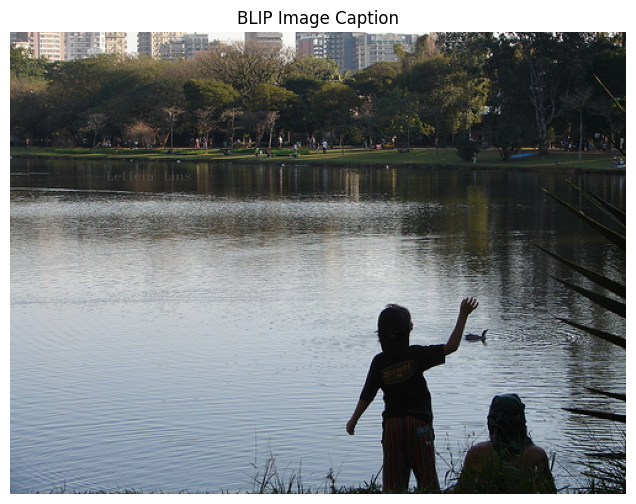

Image filename: 1022454332_6af2c1449a.jpg
Image path: C:\Users\rajva\Desktop\image-captioning Project\data\raw\Images\1022454332_6af2c1449a.jpg
BLIP caption: a body of water


In [10]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import torch

# Existing dataset image folder
image_dir = Path(
    r"C:\Users\rajva\Desktop\image-captioning Project\data\raw\Images"
)

# Select one image for the initial test
image_files = sorted(image_dir.glob("*.jpg"))

if not image_files:
    raise FileNotFoundError(
        f"No JPG images found in: {image_dir}"
    )

test_image_path = image_files[16]

# Open and convert image to RGB
image = Image.open(test_image_path).convert("RGB")

# Prepare image for BLIP
inputs = blip_processor(
    images=image,
    return_tensors="pt"
).to(device)

# Generate caption
with torch.inference_mode():
    output_ids = blip_model.generate(
        **inputs,
        max_new_tokens=40
    )

blip_caption = blip_processor.decode(
    output_ids[0],
    skip_special_tokens=True
)

# Display image and caption
plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.title("BLIP Image Caption")
plt.show()

print("Image filename:", test_image_path.name)
print("Image path:", test_image_path)
print("BLIP caption:", blip_caption)


In [11]:

import sys
from pathlib import Path

PROJECT_DIR = Path(
    r"C:\Users\rajva\Desktop\image-captioning Project"
)

# Make the project directory available for imports
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

# Import the existing custom model functions
from app import (
    load_captioning_model,
    extract_vit_patch_tokens,
    generate_caption,
    generate_multiple_captions,
    DEVICE,
)

print("Loading the existing ViT + Transformer model...")

(
    vit_model,
    decoder,
    vit_transform,
    id_to_word,
    vocab_data,
    model_info,
) = load_captioning_model()

print("\nCustom model loaded successfully!")
print("Device:", DEVICE)
print("Vocabulary size:", len(vocab_data))
print("Checkpoint epoch:", model_info["epoch"])
print("Saved validation loss:", model_info["val_loss"])


2026-10-24 10:30:36.122 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-24 10:30:36.146 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-24 10:30:38.186 
  command:

    streamlit run C:\Users\rajva\anaconda3\envs\image_captioning\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-10-24 10:30:38.188 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-24 10:30:38.190 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-24 10:30:38.192 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-24 10:30:38.193 Thread 'MainThread': missing ScriptRunContext! This warning ca

Loading the existing ViT + Transformer model...

Custom model loaded successfully!
Device: cpu
Vocabulary size: 12076
Checkpoint epoch: 6
Saved validation loss: 3.198484966344772


## Compare both models on the same image

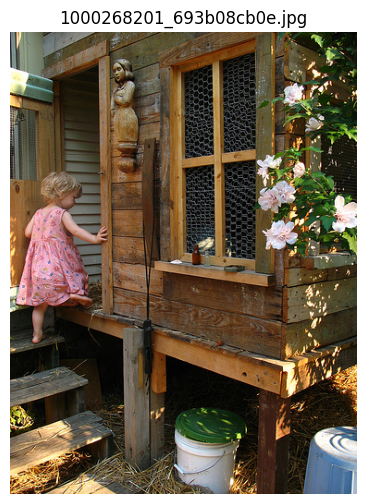

IMAGE CAPTIONING COMPARISON

BLIP caption:
a little girl in a pink dress

Custom ViT + Transformer caption:
a little girl in a pink dress is climbing a wooden fence.

Feature shape: (1, 196, 768)
Both models tested on the same image.


In [12]:

from pathlib import Path
from PIL import Image
import torch
import matplotlib.pyplot as plt

# Use the exact same image tested with BLIP
test_image_path = Path(
    r"C:\Users\rajva\Desktop\image-captioning Project"
    r"\data\raw\Images\1000268201_693b08cb0e.jpg"
)

if not test_image_path.is_file():
    raise FileNotFoundError(
        f"Image not found: {test_image_path}"
    )

image = Image.open(test_image_path).convert("RGB")

# --------------------------------------------------
# 1. BLIP prediction
# --------------------------------------------------
blip_inputs = blip_processor(
    images=image,
    return_tensors="pt"
).to(device)

with torch.inference_mode():
    blip_output_ids = blip_model.generate(
        **blip_inputs,
        max_new_tokens=40
    )

blip_caption = blip_processor.decode(
    blip_output_ids[0],
    skip_special_tokens=True
)

# --------------------------------------------------
# 2. Custom ViT + Transformer prediction
# --------------------------------------------------
image_tensor = vit_transform(image).unsqueeze(0).to(DEVICE)

visual_features = extract_vit_patch_tokens(
    image_tensor,
    vit_model
)

custom_caption = generate_caption(
    visual_features,
    decoder,
    id_to_word,
    vocab_data
)

# --------------------------------------------------
# 3. Display the comparison
# --------------------------------------------------
plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.title(test_image_path.name)
plt.show()

print("=" * 60)
print("IMAGE CAPTIONING COMPARISON")
print("=" * 60)
print("\nBLIP caption:")
print(blip_caption)

print("\nCustom ViT + Transformer caption:")
print(custom_caption)

print("\nFeature shape:", tuple(visual_features.shape))
print("Both models tested on the same image.")



In [13]:

from pathlib import Path

external_image_path = Path(
    r"C:\Users\rajva\Desktop\external_test.jpg"
)

print("Image exists:", external_image_path.is_file())
print("Image path:", external_image_path)

if external_image_path.is_file():
    print("Ready for external-image comparison.")
else:
    print("Please save your test image at this path.")


Image exists: False
Image path: C:\Users\rajva\Desktop\external_test.jpg
Please save your test image at this path.


## Find an external test image

In [21]:

from pathlib import Path
from PIL import Image

# Replace this with the path copied from File Explorer
external_image_path = Path(
    r"C:\Users\rajva\Desktop\test_images\classrom.jpg"
)

if not external_image_path.is_file():
    print("Image not found. Check the path and filename.")
else:
    with Image.open(external_image_path) as img:
        print("Image found:", external_image_path.name)
        print("Image dimensions:", img.size)
        print("Image format:", img.format)

    print("Ready for BLIP vs. custom model comparison.")


Image found: classrom.jpg
Image dimensions: (5328, 4000)
Image format: JPEG
Ready for BLIP vs. custom model comparison.


## Generate captions from both models

In [24]:
from PIL import Image
import torch
from pathlib import Path

# External test image
external_image_path = Path(
    r"C:\Users\rajva\Desktop\test_images\classrom.jpg"
)

# Load image
image = Image.open(external_image_path).convert("RGB")

# -----------------------------
# 1. BLIP caption
# -----------------------------
blip_inputs = blip_processor(
    images=image,
    return_tensors="pt"
).to(device)

with torch.inference_mode():
    blip_output_ids = blip_model.generate(
        **blip_inputs,
        max_new_tokens=40
    )

blip_caption = blip_processor.decode(
    blip_output_ids[0],
    skip_special_tokens=True
)

# -----------------------------
# 2. Custom ViT + Transformer
# -----------------------------
image_tensor = vit_transform(image).unsqueeze(0).to(DEVICE)

with torch.inference_mode():
    visual_features = extract_vit_patch_tokens(
        image_tensor, vit_model
    )

custom_caption = generate_caption(
    visual_features,
    decoder,
    id_to_word,
    vocab_data
)

# -----------------------------
# 3. Display comparison
# -----------------------------
print("=" * 55)
print("EXTERNAL IMAGE CAPTIONING COMPARISON")
print("=" * 55)

print("\nBLIP caption:")
print(blip_caption)

print("\nCustom ViT + Transformer caption:")
print(custom_caption)

print("\nImage dimensions:", image.size)
print("Custom model feature shape:", tuple(visual_features.shape))

EXTERNAL IMAGE CAPTIONING COMPARISON

BLIP caption:
a group of children standing around a table

Custom ViT + Transformer caption:
a group of people are jumping up in a room with a basketball court.

Image dimensions: (5328, 4000)
Custom model feature shape: (1, 196, 768)


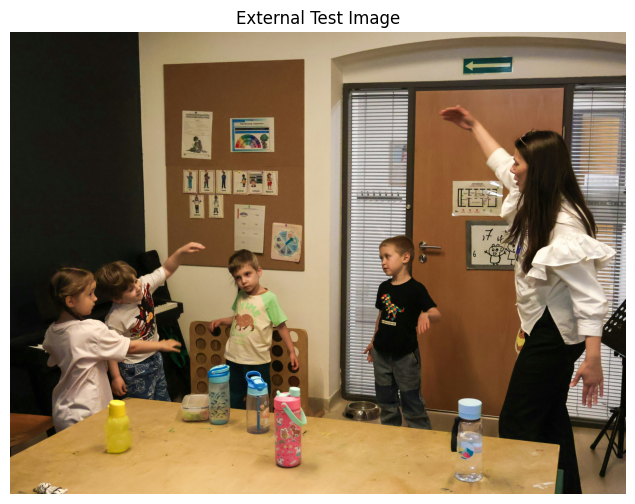

BLIP: a group of children standing around a table
Custom ViT + Transformer: a group of people are jumping up in a room with a basketball court.


In [25]:
import matplotlib.pyplot as plt
from PIL import Image

image = Image.open(external_image_path).convert("RGB")

plt.figure(figsize=(10, 6))
plt.imshow(image)
plt.axis("off")
plt.title("External Test Image")
plt.show()

print("BLIP:", blip_caption)
print("Custom ViT + Transformer:", custom_caption)

In [27]:
from pathlib import Path

test_images_dir = Path(
    r"C:\Users\rajva\Desktop\test_images"
)

valid_extensions = {".jpg", ".jpeg", ".png", ".webp"}

image_paths = sorted(
    p for p in test_images_dir.iterdir()
    if p.is_file() and p.suffix.lower() in valid_extensions
)

print("Test images found:", len(image_paths))

for i, path in enumerate(image_paths, start=1):
    print(f"{i}. {path.name}")

Test images found: 10
1. city.jpg
2. classrom.jpg
3. cycle.jpg
4. dog.jpg
5. football.jpg
6. kid.jpg
7. man.jpg
8. sea.jpg
9. student.jpg
10. walk.jpg


In [28]:

import time
import pandas as pd
from PIL import Image
import torch
from pathlib import Path
from IPython.display import display

test_images_dir = Path(
    r"C:\Users\rajva\Desktop\test_images"
)

valid_extensions = {".jpg", ".jpeg", ".png", ".webp"}

image_paths = sorted(
    p for p in test_images_dir.iterdir()
    if p.is_file() and p.suffix.lower() in valid_extensions
)

results = []

for image_path in image_paths:
    image = Image.open(image_path).convert("RGB")

    # -------------------------
    # 1. BLIP caption and time
    # -------------------------
    start = time.perf_counter()

    blip_inputs = blip_processor(
        images=image, return_tensors="pt"
    ).to(device)

    with torch.inference_mode():
        blip_ids = blip_model.generate(
            **blip_inputs,
            max_new_tokens=40
        )

    blip_caption = blip_processor.decode(
        blip_ids[0], skip_special_tokens=True
    )

    blip_time = time.perf_counter() - start

    # --------------------------------
    # 2. Custom model caption and time
    # --------------------------------
    start = time.perf_counter()

    image_tensor = vit_transform(image).unsqueeze(0).to(DEVICE)

    with torch.inference_mode():
        visual_features = extract_vit_patch_tokens(
            image_tensor, vit_model
        )

    custom_caption = generate_caption(
        visual_features,
        decoder,
        id_to_word,
        vocab_data
    )

    custom_time = time.perf_counter() - start

    results.append({
        "Image": image_path.name,
        "BLIP Caption": blip_caption,
        "Custom Caption": custom_caption,
        "BLIP Time (s)": round(blip_time, 3),
        "Custom Time (s)": round(custom_time, 3)
    })

    print(f"Completed {len(results)}/{len(image_paths)}: {image_path.name}")

# Create and display the results table
comparison_df = pd.DataFrame(results)

display(comparison_df)

# Save results without changing your model or app
output_path = test_images_dir / "blip_vs_custom_results.csv"
comparison_df.to_csv(output_path, index=False)

print("\nResults saved to:", output_path)
print("Total images evaluated:", len(comparison_df))


Completed 1/10: city.jpg
Completed 2/10: classrom.jpg
Completed 3/10: cycle.jpg
Completed 4/10: dog.jpg
Completed 5/10: football.jpg
Completed 6/10: kid.jpg
Completed 7/10: man.jpg
Completed 8/10: sea.jpg
Completed 9/10: student.jpg
Completed 10/10: walk.jpg


,Image,BLIP Caption,Custom Caption,BLIP Time (s),Custom Time (s)
0,city.jpg,a long line of cars,a group of people are riding on a city street ...,4.437,2.537
1,classrom.jpg,a group of children standing around a table,a group of people are jumping up in a room wit...,2.794,0.928
2,cycle.jpg,a group of people riding bikes on a bridge,a group of people are riding bicycles on a cit...,2.401,0.671
3,dog.jpg,a dog standing in the leaves,a brown and white dog is standing in the leaves.,2.540,0.887
4,football.jpg,a group of young boys playing soccer on a field,a group of boys playing soccer,2.415,0.653
5,kid.jpg,a little girl is playing with a colorful paper,a boy in a striped shirt is sitting on a blue ...,2.337,0.674
6,man.jpg,a young boy sitting on the ground with a box o...,a boy is playing with a small ball on a sidewalk,2.906,0.759
7,sea.jpg,a boy standing in the water,a boy stands in the water.,2.670,0.815
8,student.jpg,a boy and a boy sitting at a table,a woman sitting in a room with a black and a m...,2.551,1.088
9,walk.jpg,a group of people standing on a street,a group of people are riding down a railing wi...,2.232,0.721



Results saved to: C:\Users\rajva\Desktop\test_images\blip_vs_custom_results.csv
Total images evaluated: 10


## Score caption accuracy consistently

In [29]:

# Manual evaluation table for the 10 external images.
# Enter scores after inspecting each image.
# 2 = accurate, 1 = partially accurate, 0 = inaccurate.

import pandas as pd
from IPython.display import display

evaluation_df = comparison_df[[
    "Image", "BLIP Caption", "Custom Caption"
]].copy()

evaluation_df["BLIP Score (0-2)"] = None
evaluation_df["Custom Score (0-2)"] = None
evaluation_df["Notes"] = ""

display(evaluation_df)

# Save a separate file so the original caption results remain unchanged.
evaluation_path = test_images_dir / "manual_accuracy_evaluation.csv"
evaluation_df.to_csv(evaluation_path, index=False)

print("Evaluation template saved to:", evaluation_path)


,Image,BLIP Caption,Custom Caption,BLIP Score (0-2),Custom Score (0-2),Notes
0,city.jpg,a long line of cars,a group of people are riding on a city street ...,None,None,
1,classrom.jpg,a group of children standing around a table,a group of people are jumping up in a room wit...,None,None,
2,cycle.jpg,a group of people riding bikes on a bridge,a group of people are riding bicycles on a cit...,None,None,
3,dog.jpg,a dog standing in the leaves,a brown and white dog is standing in the leaves.,None,None,
4,football.jpg,a group of young boys playing soccer on a field,a group of boys playing soccer,None,None,
5,kid.jpg,a little girl is playing with a colorful paper,a boy in a striped shirt is sitting on a blue ...,None,None,
6,man.jpg,a young boy sitting on the ground with a box o...,a boy is playing with a small ball on a sidewalk,None,None,
7,sea.jpg,a boy standing in the water,a boy stands in the water.,None,None,
8,student.jpg,a boy and a boy sitting at a table,a woman sitting in a room with a black and a m...,None,None,
9,walk.jpg,a group of people standing on a street,a group of people are riding down a railing wi...,None,None,


Evaluation template saved to: C:\Users\rajva\Desktop\test_images\manual_accuracy_evaluation.csv


## Visual evaluation gallery 

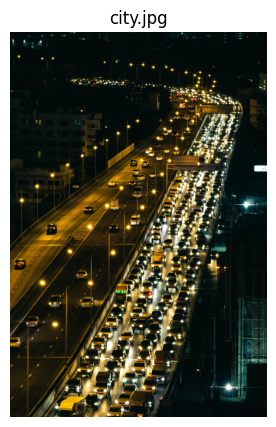

BLIP:    a long line of cars
Custom:  a group of people are riding on a city street corner.
----------------------------------------------------------------------


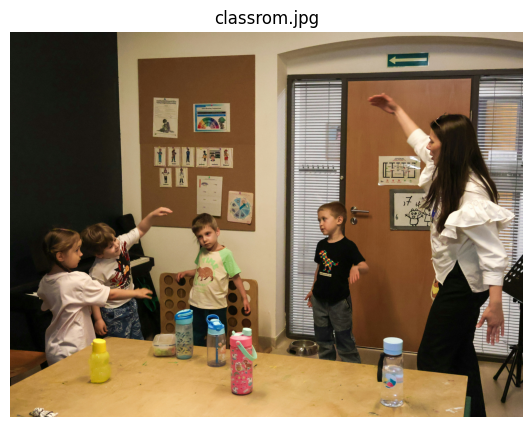

BLIP:    a group of children standing around a table
Custom:  a group of people are jumping up in a room with a basketball court.
----------------------------------------------------------------------


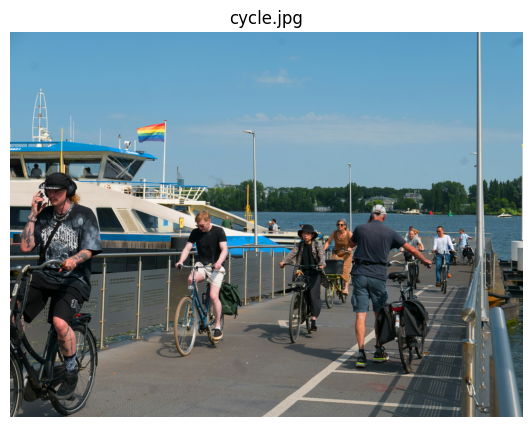

BLIP:    a group of people riding bikes on a bridge
Custom:  a group of people are riding bicycles on a city street.
----------------------------------------------------------------------


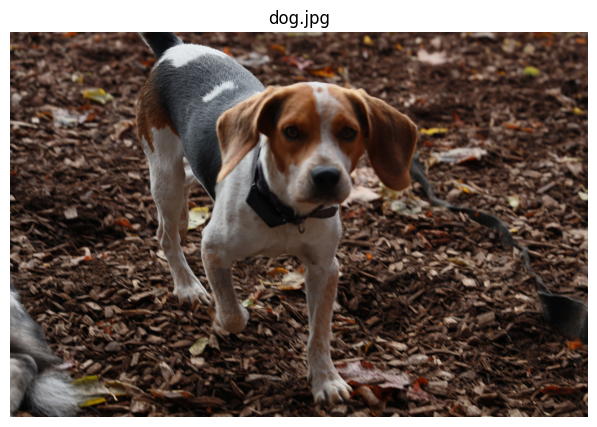

BLIP:    a dog standing in the leaves
Custom:  a brown and white dog is standing in the leaves.
----------------------------------------------------------------------


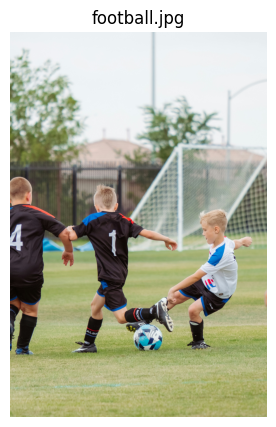

BLIP:    a group of young boys playing soccer on a field
Custom:  a group of boys playing soccer
----------------------------------------------------------------------


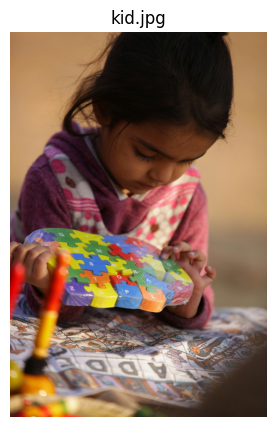

BLIP:    a little girl is playing with a colorful paper
Custom:  a boy in a striped shirt is sitting on a blue blanket.
----------------------------------------------------------------------


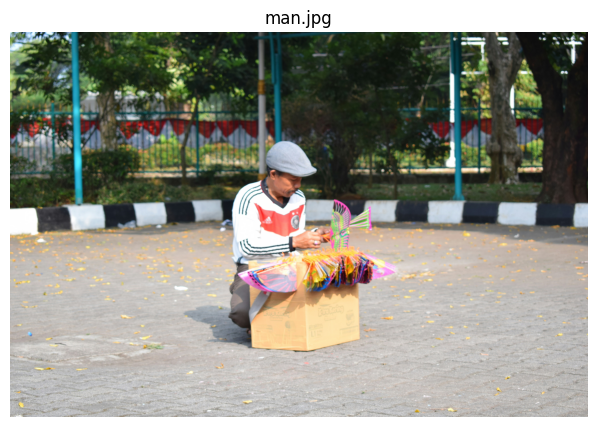

BLIP:    a young boy sitting on the ground with a box of kites
Custom:  a boy is playing with a small ball on a sidewalk
----------------------------------------------------------------------


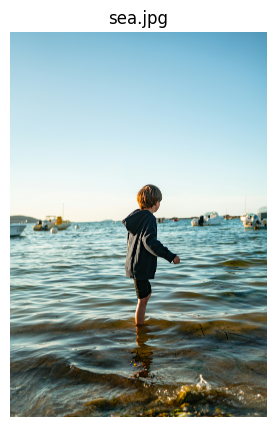

BLIP:    a boy standing in the water
Custom:  a boy stands in the water.
----------------------------------------------------------------------


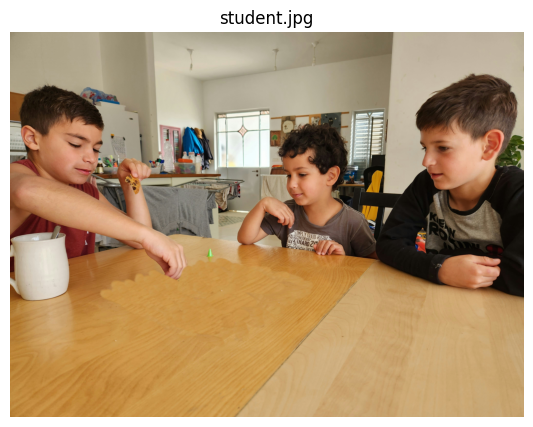

BLIP:    a boy and a boy sitting at a table
Custom:  a woman sitting in a room with a black and a man in a black shirt and white shirt and a black shirt on a table with a man in a room
----------------------------------------------------------------------


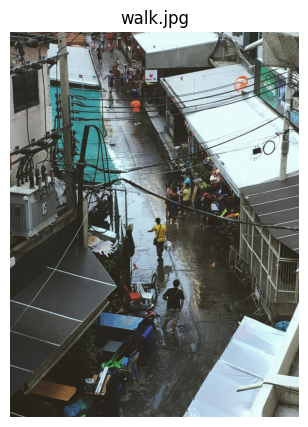

BLIP:    a group of people standing on a street
Custom:  a group of people are riding down a railing with a lot of people in the background.
----------------------------------------------------------------------


In [30]:

import matplotlib.pyplot as plt
from PIL import Image
import textwrap

for _, row in comparison_df.iterrows():
    image_path = test_images_dir / row["Image"]
    image = Image.open(image_path).convert("RGB")

    plt.figure(figsize=(8, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(row["Image"])
    plt.show()

    print("BLIP:   ", row["BLIP Caption"])
    print("Custom: ", row["Custom Caption"])
    print("-" * 70)


FINAL COMPARISON SUMMARY


,Model,Total Score,Maximum Score,Score (%),Average Time (seconds)
0,BLIP,18,20,90.0,2.728
1,Custom ViT + Transformer,10,20,50.0,0.973



IMAGE-WISE SCORES


,Image,BLIP Caption,Custom Caption,BLIP Time (s),Custom Time (s),BLIP Score,Custom Score
0,city.jpg,a long line of cars,a group of people are riding on a city street ...,4.437,2.537,2,1
1,classrom.jpg,a group of children standing around a table,a group of people are jumping up in a room wit...,2.794,0.928,2,1
2,cycle.jpg,a group of people riding bikes on a bridge,a group of people are riding bicycles on a cit...,2.401,0.671,2,2
3,dog.jpg,a dog standing in the leaves,a brown and white dog is standing in the leaves.,2.540,0.887,2,2
4,football.jpg,a group of young boys playing soccer on a field,a group of boys playing soccer,2.415,0.653,2,2
5,kid.jpg,a little girl is playing with a colorful paper,a boy in a striped shirt is sitting on a blue ...,2.337,0.674,2,0
6,man.jpg,a young boy sitting on the ground with a box o...,a boy is playing with a small ball on a sidewalk,2.906,0.759,2,0
7,sea.jpg,a boy standing in the water,a boy stands in the water.,2.670,0.815,2,2
8,student.jpg,a boy and a boy sitting at a table,a woman sitting in a room with a black and a m...,2.551,1.088,1,0
9,walk.jpg,a group of people standing on a street,a group of people are riding down a railing wi...,2.232,0.721,1,0


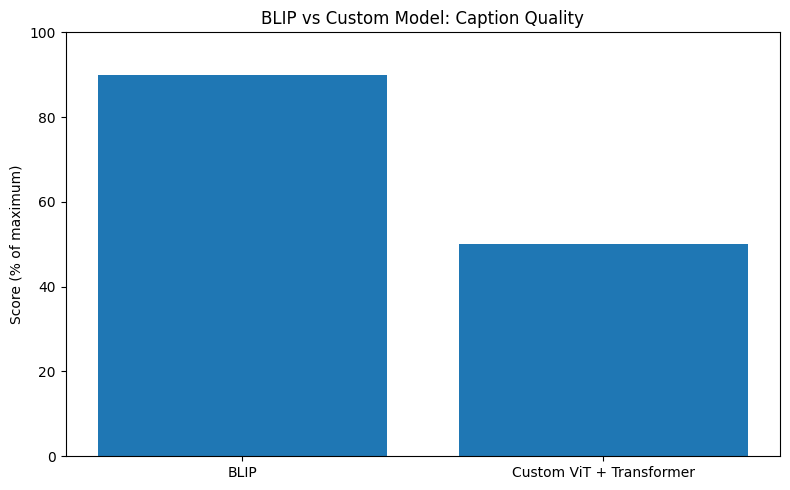

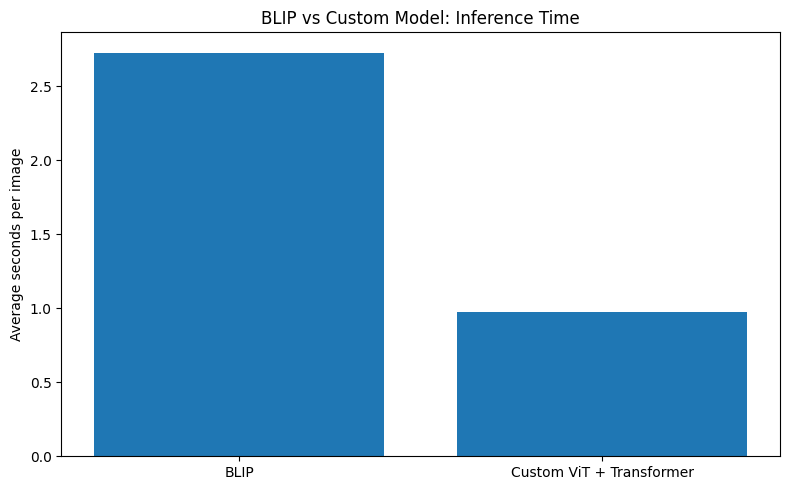


Saved:
C:\Users\rajva\Desktop\test_images\final_blip_custom_evaluation.csv
C:\Users\rajva\Desktop\test_images\final_model_summary.csv


In [31]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

# Preliminary manual scores from our visual review
manual_scores = {
    "city.jpg":      (2, 1),
    "classrom.jpg":  (2, 1),
    "cycle.jpg":     (2, 2),
    "dog.jpg":       (2, 2),
    "football.jpg":  (2, 2),
    "kid.jpg":       (2, 0),
    "man.jpg":       (2, 0),
    "sea.jpg":       (2, 2),
    "student.jpg":   (1, 0),
    "walk.jpg":      (1, 0),
}

# Build a separate scored results table
final_df = comparison_df.copy()

final_df["BLIP Score"] = final_df["Image"].map(
    lambda name: manual_scores[name][0]
)
final_df["Custom Score"] = final_df["Image"].map(
    lambda name: manual_scores[name][1]
)

# Summary statistics
blip_total = final_df["BLIP Score"].sum()
custom_total = final_df["Custom Score"].sum()

summary_df = pd.DataFrame({
    "Model": ["BLIP", "Custom ViT + Transformer"],
    "Total Score": [blip_total, custom_total],
    "Maximum Score": [20, 20],
    "Score (%)": [
        blip_total / 20 * 100,
        custom_total / 20 * 100
    ],
    "Average Time (seconds)": [
        final_df["BLIP Time (s)"].mean(),
        final_df["Custom Time (s)"].mean()
    ]
})

print("FINAL COMPARISON SUMMARY")
display(summary_df.round(3))

print("\nIMAGE-WISE SCORES")
display(final_df)

# Chart 1: Qualitative caption scores
plt.figure(figsize=(8, 5))
plt.bar(
    summary_df["Model"],
    summary_df["Score (%)"]
)
plt.ylabel("Score (% of maximum)")
plt.title("BLIP vs Custom Model: Caption Quality")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

# Chart 2: Average inference time
plt.figure(figsize=(8, 5))
plt.bar(
    summary_df["Model"],
    summary_df["Average Time (seconds)"]
)
plt.ylabel("Average seconds per image")
plt.title("BLIP vs Custom Model: Inference Time")
plt.tight_layout()
plt.show()

# Save results separately; original CSV remains unchanged
output_dir = Path(
    r"C:\Users\rajva\Desktop\test_images"
)

final_df.to_csv(
    output_dir / "final_blip_custom_evaluation.csv",
    index=False
)

summary_df.to_csv(
    output_dir / "final_model_summary.csv",
    index=False
)

print("\nSaved:")
print(output_dir / "final_blip_custom_evaluation.csv")
print(output_dir / "final_model_summary.csv")
